# 06 Diagnostics: where personalisation helps, and the report figures

**Purpose.** Describe the final rankers of `05_models` and `05b_neural` on `validation_clean`: for whom and where personalisation helps, how often it hurts, and what happens to products that nobody has interacted with before. It also draws the report figures. This is E32 in `docs/EXPERIMENT_LOG.md` (question, expectation and segment bins written before running).

**Rules.**
- **No training and no new models.** The notebook only reads saved validation scores: the full-data LambdaMART base, M1 and M1 + CF (05 section 14), the feature MLP and the regularised history attention (05b); lagged popularity and own-product counts come from the v3 validation features, and the E30 rule is rebuilt with 05's formula.
- **Same numbers as the registry.** Every ranking's overall NDCG@10 must match its row in `docs/experiment_results.csv` before any segment is read.
- **Descriptive only.** Segment results are paired per-search differences with bootstrap intervals over searches (1,000 resamples); there is no decision rule here, and small cells are not interpreted on their own. The test set is not touched.
- Population `validation_clean` (18,844 searches: an engaged candidate, no clamped final gap).

**How to run.** On Colab (CPU is enough): open this notebook from GitHub (branch `BRANCH` below); the first cell clones the repository and mounts Drive. It reads `search_table.parquet`, `split_v1.csv`, `features_v3_validation.parquet` and the `neural/` folder from `MyDrive/BT4222 Group Project/processed/`, and writes tables and figures to `MyDrive/BT4222 Group Project/outputs/diagnostics/`. Locally it reads `data/processed/` and writes `outputs/diagnostics/`. A few minutes.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BRANCH = "feat/diagnostics"  # branch to clone on Colab; "main" once merged
REPO_ROOT = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/evaluation.py").is_file()), None)
if REPO_ROOT is None and IN_COLAB:  # opened from GitHub: clone the (public) repository, or update an earlier clone
    import subprocess
    REPO_ROOT = Path("/content/BT4222-group17-jdsearch")
    if (REPO_ROOT / ".git").is_dir():  # a second run in the same runtime: bring the clone to the branch's latest commit
        subprocess.run(["git", "-C", str(REPO_ROOT), "fetch", "--depth", "1", "origin", BRANCH], check=True)
        subprocess.run(["git", "-C", str(REPO_ROOT), "reset", "--hard", "FETCH_HEAD"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH,
                        "https://github.com/liamkunert/BT4222-group17-jdsearch.git", str(REPO_ROOT)], check=True)
if REPO_ROOT is None:
    raise FileNotFoundError("Open/clone the repository checkout first.")
if IN_COLAB:
    drive.mount("/content/drive")
    PROCESSED = Path("/content/drive/MyDrive/BT4222 Group Project/processed")
    OUTPUTS = Path("/content/drive/MyDrive/BT4222 Group Project/outputs/diagnostics")
else:
    PROCESSED = REPO_ROOT / "data/processed"
    OUTPUTS = REPO_ROOT / "outputs/diagnostics"
OUTPUTS.mkdir(parents=True, exist_ok=True)
NEURAL_DIR = PROCESSED / "neural"

sys.path.insert(0, str(REPO_ROOT))
from scripts.evaluation import RESULTS, bootstrap_interval, evaluate, paired_difference, summarise

# Code check only: evaluate a random subset of validation searches (registry check skipped). Unset for the real run.
CHECK_SEARCHES = int(os.environ.get("DIAG_CHECK_SEARCHES", "0")) or None
SEED = 4222
pd.options.display.float_format = "{:,.4f}".format

# Figure style: recessive axes and grid, text in ink colours, categorical hues in a fixed order.
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
NEUTRAL, NEUTRAL_LIGHT = "#8f8e89", "#cfcec9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
WIN, LOSS = "#2a78d6", "#e34948"  # diverging pair (blue / red) with a grey midpoint for ties
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110,
    "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})


def save(fig, name):
    fig.savefig(OUTPUTS / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


print(f"processed data: {PROCESSED}; outputs: {OUTPUTS}; code check on {CHECK_SEARCHES or 'all'} searches")

Mounted at /content/drive
processed data: /content/drive/MyDrive/BT4222 Group Project/processed; outputs: /content/drive/MyDrive/BT4222 Group Project/outputs/diagnostics; code check on all searches


## 1. Rankings and consistency check

Seven rankings of every validation list. Scores are aligned row by row with the v3 validation file (the order in which 05 and 05b wrote them); the rule is 05's E30 formula: own-product count first, then the trained base's score rescaled to [0, 0.999].

In [2]:
searches = pd.read_parquet(PROCESSED / "search_table.parquet")
assignment = pd.read_csv(PROCESSED / "split_v1.csv", index_col="session_id")
validation_ids = assignment.index[assignment.split == "validation"]
frame = pq.read_table(PROCESSED / "features_v3_validation.parquet",
                      columns=["session_id", "wid", "label", "pooled_product", "pop_history_lag1d"]).to_pandas()


def scores_of(name, columns=("score",)):
    """Saved validation scores of one model, checked against the row order of the v3 validation file."""
    scores = pd.read_parquet(NEURAL_DIR / f"{name}_validation_scores.parquet")
    assert (scores.session_id.to_numpy() == frame.session_id.to_numpy()).all()
    assert "wid" not in scores or (scores.wid.to_numpy() == frame.wid.to_numpy()).all()
    return [scores[c].to_numpy(dtype=float) for c in columns]


base, m1, m1_cf = scores_of("lambdamart", ("base", "m1", "m1_cf"))
own = frame.pooled_product.fillna(0).to_numpy(dtype=float)
RANKINGS = {
    "lagged popularity": frame.pop_history_lag1d.fillna(0).to_numpy(dtype=float),
    "LambdaMART base": base,
    "rule: own products first, then the base": own + 0.999 * (base - base.min()) / (base.max() - base.min()),
    "M1: base + pooled history": m1,
    "M1 + CF": m1_cf,
    "feature MLP": scores_of("mlp")[0],
}
ATTENTION = "history attention v3 (regularised)"
if (NEURAL_DIR / "attention_v3_validation_scores.parquet").is_file():
    RANKINGS[ATTENTION] = scores_of("attention_v3")[0]
else:  # only acceptable for a local code check; on Colab the file is on Drive
    assert CHECK_SEARCHES, "attention_v3_validation_scores.parquet is missing"
    print("attention v3 scores not found: left out (code check only)")
for name, score in RANKINGS.items():
    frame[name] = score

sizes = searches.loc[validation_ids, "n_candidates"]
if CHECK_SEARCHES:
    sample = np.random.default_rng(SEED).choice(validation_ids.to_numpy(), size=CHECK_SEARCHES, replace=False)
    frame, sizes = frame[frame.session_id.isin(sample)].reset_index(drop=True), sizes.loc[np.sort(sample)]
per_search = {name: evaluate(frame, name, expected_sizes=sizes) for name in RANKINGS}
all_ids = per_search["LambdaMART base"].index
clean_ids = all_ids[~searches.final_gap_clamped.reindex(all_ids).to_numpy()]
print(f"{len(all_ids):,} validation searches with an engaged candidate; validation_clean {len(clean_ids):,}")

# Same numbers as the registry (rounded to five decimals there). Only the E31 row may be missing: it is logged when 05
# section 15 next runs; every other ranking must have its row.
REGISTRY_ROWS = {
    "lagged popularity": ("E13", "history popularity, lag 1 day"),
    "LambdaMART base": ("E23", "base, all training"),
    "rule: own products first, then the base": ("E30", "rule: own products first, then the trained base"),
    "M1: base + pooled history": ("E23", "M1, all training"),
    "M1 + CF": ("E23", "M1 + CF, all training"),
    "feature MLP": ("E27", "feature MLP"),
    ATTENTION: ("E31", "history attention v3 (regularised)"),
}
registry = pd.read_csv(RESULTS)
rows = {}
for name in RANKINGS:
    experiment, model = REGISTRY_ROWS[name]
    logged = registry.query("experiment == @experiment and model == @model and split == 'validation_clean'")
    here = per_search[name].ndcg.loc[clean_ids].mean()
    rows[name] = {"NDCG@10 here": here, "registry": logged.ndcg_at_10.iloc[0] if len(logged) else np.nan}
    if not CHECK_SEARCHES:
        assert len(logged) or experiment == "E31", f"{name}: no registry row"
        assert not len(logged) or abs(here - logged.ndcg_at_10.iloc[0]) < 6e-6, name
pd.DataFrame(rows).T

19,772 validation searches with an engaged candidate; validation_clean 18,844


,NDCG@10 here,registry
lagged popularity,0.3374,0.3375
LambdaMART base,0.3500,0.3499
"rule: own products first, then the base",0.3840,0.3840
M1: base + pooled history,0.3887,0.3887
M1 + CF,0.3918,0.3918
feature MLP,0.3889,0.3889
history attention v3 (regularised),0.3867,NaN


## 2. Results ladder (Figure 1)

All rankings on `validation_clean` with 95% bootstrap intervals (each ranking's own interval, not paired differences). Random order, Team 3 and attention v1 / v2 come from the registry; the rest is computed above. **One exception to the population:** our re-implementation of Team 3's model (R0, E11) was evaluated on all 19,772 validation searches, including the clamped ones; it is marked in its label and in the axis title.

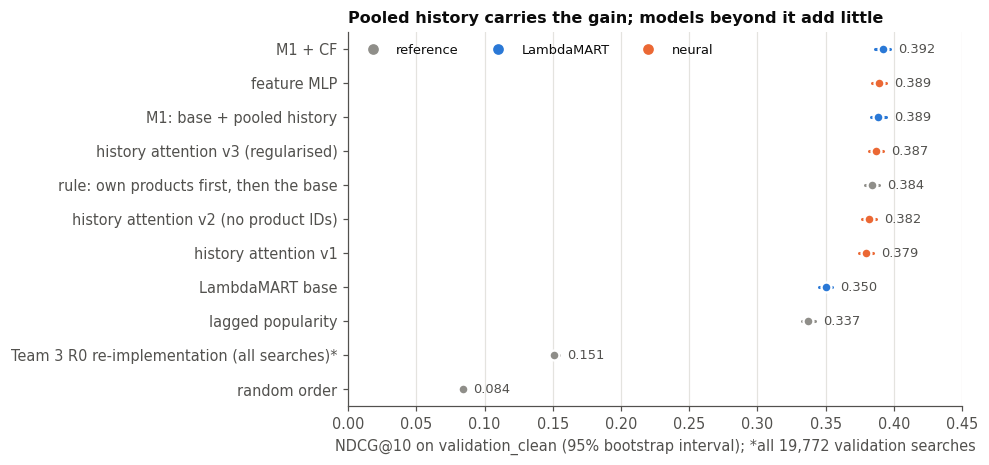

,ranking,family,ndcg,low,high
0,random order,reference,0.0842,0.0828,0.0858
1,Team 3 R0 re-implementation (all searches)*,reference,0.1510,0.1477,0.1546
2,lagged popularity,reference,0.3374,0.3327,0.3423
3,LambdaMART base,LambdaMART,0.3500,0.3453,0.3547
4,history attention v1,neural,0.3795,0.3744,0.3845
5,history attention v2 (no product IDs),neural,0.3816,0.3766,0.3867
6,"rule: own products first, then the base",reference,0.3840,0.3790,0.3895
7,history attention v3 (regularised),neural,0.3867,0.3818,0.3920
8,M1: base + pooled history,LambdaMART,0.3887,0.3837,0.3941
9,feature MLP,neural,0.3889,0.3837,0.3940


In [3]:
def from_registry(experiment, model, split="validation_clean"):
    row = registry.query("experiment == @experiment and model == @model and split == @split").iloc[0]
    return row.ndcg_at_10, row.ndcg_ci_low, row.ndcg_ci_high


FAMILY = {"reference": NEUTRAL, "LambdaMART": SERIES[0], "neural": SERIES[1]}
ladder = [
    ("random order", "reference", from_registry("E13", "random order")),
    ("Team 3 R0 re-implementation (all searches)*", "reference",
     from_registry("E11", "Team 3 ladder R0 as published", "validation")),
    ("history attention v1", "neural", from_registry("E28", "history attention v1")),
    ("history attention v2 (no product IDs)", "neural", from_registry("E29", "history attention v2 (no product IDs)")),
]
FAMILY_OF = {"lagged popularity": "reference", "rule: own products first, then the base": "reference",
             "feature MLP": "neural", ATTENTION: "neural"}
for name in RANKINGS:
    s = summarise(per_search[name].loc[clean_ids]).iloc[0]
    ladder.append((name, FAMILY_OF.get(name, "LambdaMART"), (s.ndcg_at_10, s.ndcg_ci_low, s.ndcg_ci_high)))
ladder = pd.DataFrame([(n, f, *v) for n, f, v in ladder], columns=["ranking", "family", "ndcg", "low", "high"])
ladder = ladder.sort_values("ndcg").reset_index(drop=True)
ladder.to_csv(OUTPUTS / "fig1_results_ladder.csv", index=False)

fig, ax = plt.subplots(figsize=(7.2, 0.32 * len(ladder) + 0.9))
for i, r in ladder.iterrows():
    color = FAMILY[r.family]
    ax.plot([r.low, r.high], [i, i], color=color, linewidth=2, solid_capstyle="round")
    ax.scatter(r.ndcg, i, s=42, color=color, edgecolor="white", linewidth=1.5, zorder=3)
    ax.text(r.high + 0.006, i, f"{r.ndcg:.3f}", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(range(len(ladder)), ladder.ranking)
ax.set_xlim(0, 0.45)
ax.grid(axis="y", visible=False)
ax.set_xlabel("NDCG@10 on validation_clean (95% bootstrap interval); *all 19,772 validation searches")
ax.set_title("Pooled history carries the gain; models beyond it add little")
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, markersize=6, label=f) for f, c in FAMILY.items()]
ax.legend(handles=handles, loc="upper left", ncol=3, fontsize=8.5)
save(fig, "fig1_results_ladder")
ladder

## 3. Personal gain by segment (Figure 2)

Two paired comparisons per segment, fixed before running (E32): the **personal gain** M1 minus base, and **what learning adds beyond "own products first"**, M1 minus the rule. "Share of the gain" is the segment's part of the summed per-search personal gain. Bins: activity in the last 7 days (as 05), history-length quartiles of `validation_clean`, list length (as 05), whether the list contains one of the shopper's own products (any `pooled_product` > 0), final gap up to 30 s or longer (E30). The intervals are pointwise and exploratory: many segments are compared, and they are not independent moderator effects. List length forms after the query (E12), so it only describes where the gain falls.

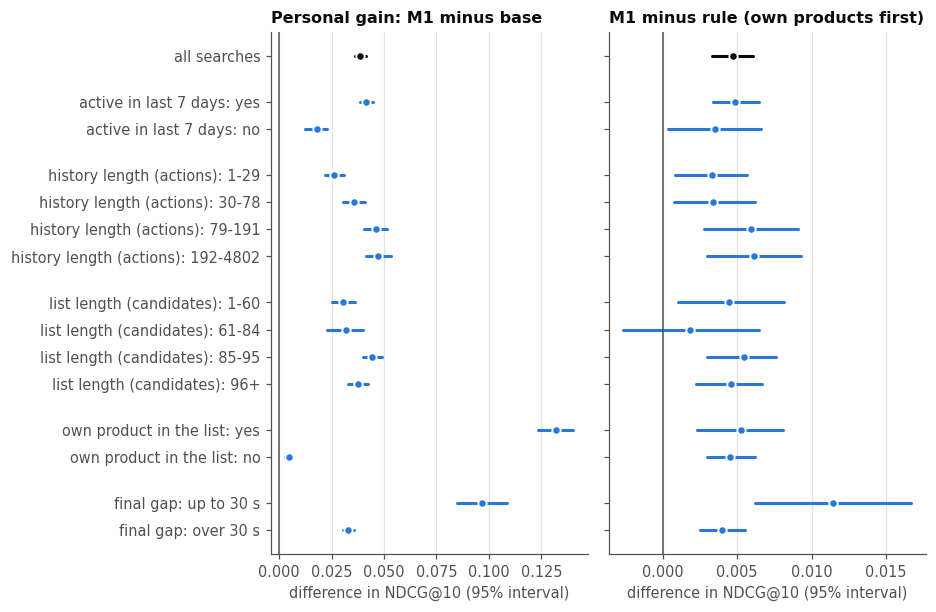

searches  share of searches  \
segment                  value                                     
all                      all            18844             1.0000   
active in last 7 days    yes            16534             0.8774   
                         no              2310             0.1226   
history length (actions) 1-29            4825             0.2560   
                         30-78           4621             0.2452   
                         79-191          4711             0.2500   
                         192-4802        4687             0.2487   
list length (candidates) 1-60            3811             0.2022   
                         61-84           1693             0.0898   
                         85-95           8613             0.4571   
                         96+             4727             0.2508   
own product in the list  yes             5060             0.2685   
                         no             13784             0.7315   
final gap                up to 30 s      1727             0.0916   
                         over 30 s      17117             0.9084   

                                     LambdaMART base  \
segment                  value                         
all                      all                  0.3500   
active in last 7 days    yes                  0.3507   
                         no                   0.3449   
history length (actions) 1-29                 0.3402   
                         30-78                0.3444   
                         79-191               0.3554   
                         192-4802             0.3600   
list length (candidates) 1-60                 0.4745   
                         61-84                0.3676   
                         85-95                0.3768   
                         96+                  0.1943   
own product in the list  yes                  0.3257   
                         no                   0.3589   
final gap                up to 30 s           0.3642   
                         over 30 s            0.3485   

                                     M1: base + pooled history  M1 - base  \
segment                  value                                              
all                      all                            0.3887     0.0387   
active in last 7 days    yes                            0.3923     0.0416   
                         no                             0.3628     0.0179   
history length (actions) 1-29                           0.3664     0.0262   
                         30-78                          0.3800     0.0355   
                         79-191                         0.4015     0.0461   
                         192-4802                       0.4074     0.0474   
list length (candidates) 1-60                           0.5048     0.0303   
                         61-84                          0.3995     0.0319   
                         85-95                          0.4211     0.0444   
                         96+                            0.2320     0.0377   
own product in the list  yes                            0.4577     0.1320   
                         no                             0.3633     0.0045   
final gap                up to 30 s                     0.4611     0.0968   
                         over 30 s                      0.3814     0.0329   

                                     M1 - base low  M1 - base high  \
segment                  value                                       
all                      all                0.0360          0.0415   
active in last 7 days    yes                0.0387          0.0446   
                         no                 0.0125          0.0228   
history length (actions) 1-29               0.0219          0.0309   
                         30-78              0.0303          0.0410   
                         79-191             0.0404          0.0514   
                         192-4802           0.0414       

In [4]:
BASE_, RULE, M1 = "LambdaMART base", "rule: own products first, then the base", "M1: base + pooled history"
info = searches.loc[clean_ids]
has_own = (frame.pooled_product.fillna(0) > 0).groupby(frame.session_id).any().reindex(clean_ids)
edges = info.history_len.quantile([0.25, 0.5, 0.75]).round().astype(int).tolist()
history_bins = [info.history_len.min() - 1, *edges, info.history_len.max()]
SEGMENTS = {
    "active in last 7 days": pd.Series(np.where(info.days_since_last_action < 7, "yes", "no"), index=clean_ids),
    "history length (actions)": pd.cut(info.history_len, history_bins,
                                       labels=[f"{lo + 1}-{hi}" for lo, hi in zip(history_bins[:-1], history_bins[1:])]),
    "list length (candidates)": pd.cut(info.n_candidates, [0, 60, 84, 95, 200], labels=["1-60", "61-84", "85-95", "96+"]),
    "own product in the list": pd.Series(np.where(has_own, "yes", "no"), index=clean_ids),
    "final gap": pd.Series(np.where(info.final_gap_s <= 30, "up to 30 s", "over 30 s"), index=clean_ids),
}
gain = per_search[M1].ndcg.loc[clean_ids] - per_search[BASE_].ndcg.loc[clean_ids]


def segment_values(labels):
    return list(labels.cat.categories) if hasattr(labels, "cat") else sorted(labels.unique(), reverse=True)


rows = []
for segment, labels in [("all", pd.Series("all", index=clean_ids)), *SEGMENTS.items()]:
    for value in segment_values(labels):
        ids = labels.index[labels == value]
        row = {"segment": segment, "value": value, "searches": len(ids), "share of searches": len(ids) / len(clean_ids)}
        row.update({name: per_search[name].ndcg.loc[ids].mean() for name in RANKINGS})
        for label, a, b in [("M1 - base", M1, BASE_), ("M1 - rule", M1, RULE)]:
            d = paired_difference(per_search[a].loc[ids], per_search[b].loc[ids])
            row.update({label: d[0], f"{label} low": d[1], f"{label} high": d[2]})
        row["share of the gain"] = gain.loc[ids].sum() / gain.sum()
        rows.append(row)
segments = pd.DataFrame(rows).set_index(["segment", "value"])
segments.to_csv(OUTPUTS / "segments.csv")

fig, axes = plt.subplots(1, 2, figsize=(8.6, 0.27 * len(segments) + 1.6), sharey=True)
y, ticks, previous = 0, [], None
positions = []
for (segment, value) in segments.index:
    if previous is not None and segment != previous:
        y += 0.7  # gap between segments
    positions.append(y)
    ticks.append(f"{segment}: {value}" if segment != "all" else "all searches")
    previous, y = segment, y + 1
positions = np.array(positions)
for ax, label, title in [(axes[0], "M1 - base", "Personal gain: M1 minus base"),
                         (axes[1], "M1 - rule", "M1 minus rule (own products first)")]:
    for pos, (_, r) in zip(positions, segments.iterrows()):
        color = INK if pos == 0 else SERIES[0]
        ax.plot([r[f"{label} low"], r[f"{label} high"]], [pos, pos], color=color, solid_capstyle="round")
        ax.scatter(r[label], pos, s=30, color=color, edgecolor="white", linewidth=1.2, zorder=3)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("difference in NDCG@10 (95% interval)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(positions, ticks)
axes[0].invert_yaxis()
fig.tight_layout()
save(fig, "fig2_gain_by_segment")
segments[["searches", "share of searches", BASE_, M1, "M1 - base", "M1 - base low", "M1 - base high",
          "share of the gain", "M1 - rule", "M1 - rule low", "M1 - rule high"]]

## 4. Wins, ties and losses (Figure 3)

How often M1 ranks a search better than, equal to or worse than the base (NDCG@10 difference above, at or below zero; a tie is usually both rankings scoring the same, often 0). Losses are where personal history pushes the shopper's actual choice down: the crowding-out risk of the business objective.

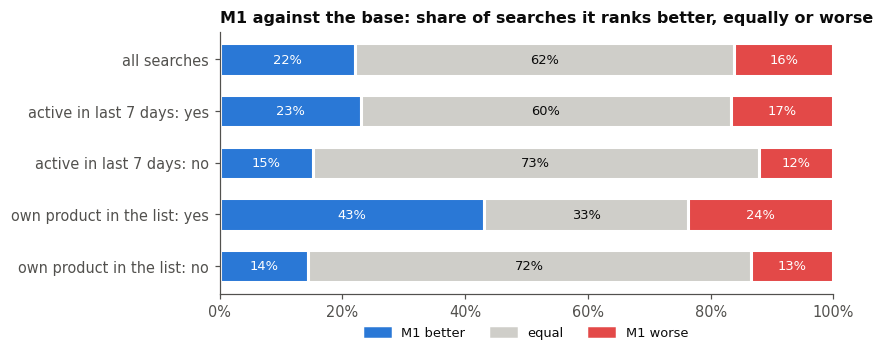

,searches,win,tie,loss,mean gain when winning,mean loss when losing
all searches,"18,844.0000",0.2214,0.6166,0.1620,0.2755,-0.1375
active in last 7 days: yes,"16,534.0000",0.2312,0.6012,0.1676,0.2824,-0.1411
active in last 7 days: no,"2,310.0000",0.1515,0.7268,0.1216,0.2005,-0.1026
own product in the list: yes,"5,060.0000",0.4312,0.3320,0.2368,0.4015,-0.1736
own product in the list: no,"13,784.0000",0.1444,0.7211,0.1345,0.1374,-0.1142


In [5]:
def outcome_shares(ids):
    d = gain.loc[ids]
    win, loss = d > 1e-9, d < -1e-9
    return {"searches": len(ids), "win": win.mean(), "tie": (~win & ~loss).mean(), "loss": loss.mean(),
            "mean gain when winning": d[win].mean(), "mean loss when losing": d[loss].mean()}


rows = {"all searches": outcome_shares(clean_ids)}
for segment in ("active in last 7 days", "own product in the list"):
    labels = SEGMENTS[segment]
    for value in segment_values(labels):
        rows[f"{segment}: {value}"] = outcome_shares(labels.index[labels == value])
outcomes = pd.DataFrame(rows).T
outcomes.to_csv(OUTPUTS / "fig3_win_tie_loss.csv")

fig, ax = plt.subplots(figsize=(7.2, 0.42 * len(outcomes) + 1.0))
for i, (name, r) in enumerate(outcomes.iterrows()):
    left = 0
    for part, color in [("win", WIN), ("tie", NEUTRAL_LIGHT), ("loss", LOSS)]:
        ax.barh(i, r[part], left=left, color=color, edgecolor="white", linewidth=2, height=0.62)
        if r[part] > 0.06:
            ax.text(left + r[part] / 2, i, f"{r[part]:.0%}", ha="center", va="center", fontsize=8.5,
                    color="white" if part != "tie" else INK)
        left += r[part]
ax.set_yticks(range(len(outcomes)), outcomes.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(False)
ax.set_title("M1 against the base: share of searches it ranks better, equally or worse")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, label=l)
           for l, c in [("M1 better", WIN), ("equal", NEUTRAL_LIGHT), ("M1 worse", LOSS)]]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8.5)
save(fig, "fig3_win_tie_loss")
outcomes

## 5. Own-history, warm and cold candidates (Figure 4)

For every **engaged** candidate: the probability of being in the top 10, exact under random tie-breaking (a tie group straddling position 10 gets its share of the remaining slots). Averaged over engaged candidates of each type, this is Recall@10 by candidate type; per search the probabilities add up to the evaluator's Recall@10 (checked). Types: **own history** (the shopper has interacted with this product: `pooled_product` > 0), otherwise **warm** (some training shopper's history action at least a day old: `pop_history_lag1d` > 0) or **cold** (neither). Differences are paired over searches (bootstrap of the ratio over whole searches).

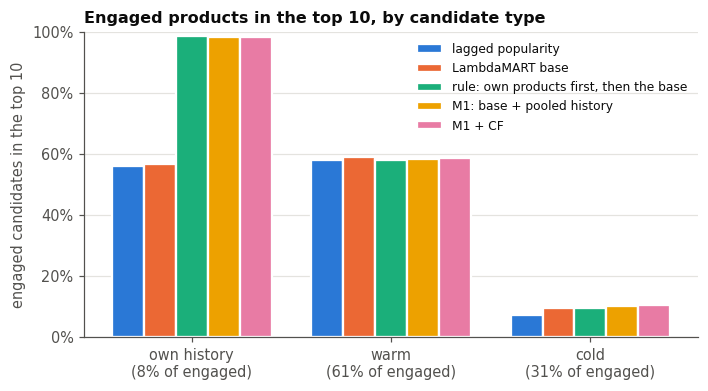

,engaged candidates,share of engaged,lagged popularity,LambdaMART base,"rule: own products first, then the base",M1: base + pooled history,M1 + CF,feature MLP,history attention v3 (regularised),M1 - base,M1 - base low,M1 - base high,lagged popularity - base,lagged popularity - base low,lagged popularity - base high
own history,"2,876.0000",0.0795,0.5601,0.5663,0.9863,0.9842,0.9826,0.9727,0.9729,0.4180,0.3989,0.4372,-0.0062,-0.0145,0.0020
warm,"21,974.0000",0.6074,0.5812,0.5897,0.5794,0.5840,0.5879,0.5831,0.5765,-0.0057,-0.0087,-0.0029,-0.0085,-0.0117,-0.0054
cold,"11,328.0000",0.3131,0.0727,0.0947,0.0936,0.1021,0.1042,0.1144,0.1179,0.0074,0.0035,0.0115,-0.0220,-0.0261,-0.0178


In [6]:
clean_frame = frame[frame.session_id.isin(clean_ids)].reset_index(drop=True)
groups = clean_frame.groupby("session_id")
for name in RANKINGS:  # exact top-10 probability under random tie-breaking
    higher = groups[name].rank(method="min", ascending=False).to_numpy() - 1
    tied = groups[name].rank(method="max", ascending=False).to_numpy() - higher
    clean_frame[f"p10 {name}"] = np.clip((10 - higher) / tied, 0, 1)
engaged = clean_frame[clean_frame.label >= 1].copy()
for name in RANKINGS:  # the probabilities reproduce the evaluator's Recall@10 per search
    recall = engaged.groupby("session_id")[f"p10 {name}"].mean()
    assert np.allclose(recall.to_numpy(), per_search[name].recall.reindex(recall.index).to_numpy(), atol=1e-9), name
engaged["type"] = np.select([engaged.pooled_product > 0, engaged.pop_history_lag1d > 0],
                            ["own history", "warm"], "cold")
TYPES = ["own history", "warm", "cold"]


def ratio_difference(part, a, b):
    """Difference in mean top-10 probability (a minus b) over the engaged candidates in `part`, with a 95% interval
    from resampling whole searches (ratio of summed differences to summed counts)."""
    per = part.groupby("session_id")
    n = per.size().to_numpy()
    diff = per[f"p10 {a}"].sum().to_numpy() - per[f"p10 {b}"].sum().to_numpy()
    draws = np.random.default_rng(SEED).integers(0, len(n), size=(1000, len(n)))
    ratios = diff[draws].sum(axis=1) / n[draws].sum(axis=1)
    return diff.sum() / n.sum(), np.quantile(ratios, 0.025), np.quantile(ratios, 0.975)


rows = {}
for kind in TYPES:
    part = engaged[engaged.type == kind]
    row = {"engaged candidates": len(part), "share of engaged": len(part) / len(engaged)}
    row.update({name: part[f"p10 {name}"].mean() for name in RANKINGS})
    for label, a, b in [("M1 - base", M1, BASE_), ("lagged popularity - base", "lagged popularity", BASE_)]:
        row.update(dict(zip([label, f"{label} low", f"{label} high"], ratio_difference(part, a, b))))
    rows[kind] = row
candidates = pd.DataFrame(rows).T
candidates.to_csv(OUTPUTS / "fig4_candidate_types.csv")

SHOWN = ["lagged popularity", BASE_, RULE, M1, "M1 + CF"]
fig, ax = plt.subplots(figsize=(7.2, 3.6))
width = 0.8 / len(SHOWN)
for j, name in enumerate(SHOWN):
    x = np.arange(len(TYPES)) + (j - (len(SHOWN) - 1) / 2) * width
    ax.bar(x, candidates.loc[TYPES, name], width=width, color=SERIES[j], edgecolor="white", linewidth=1.5, label=name)
ax.set_xticks(range(len(TYPES)), [f"{t}\n({candidates.loc[t, 'share of engaged']:.0%} of engaged)" for t in TYPES])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("engaged candidates in the top 10")
ax.grid(axis="x", visible=False)
ax.set_title("Engaged products in the top 10, by candidate type")
ax.legend(loc="upper right", fontsize=8, ncol=1)
save(fig, "fig4_candidate_types")
candidates

### Displacement and missed engagement (added after the final reviews, E33)

The averages above mix searches where M1 has an own product to promote with the 73% where it has none. **Displacement:** the top-10 probability of the *other* engaged candidates (warm and cold), M1 minus base, separately in searches whose list contains an own product and in the rest. **Missed engagement:** how many engaged candidates of each type M1 leaves outside the top 10 (expected count, and weighted by the label 1-3).

In [7]:
engaged["own product in the list"] = np.where(has_own.reindex(engaged.session_id).to_numpy(), "yes", "no")
rows = []
for value in ("yes", "no"):
    for kind, kinds in [("warm", ["warm"]), ("cold", ["cold"]), ("warm and cold", ["warm", "cold"])]:
        part = engaged[(engaged["own product in the list"] == value) & engaged.type.isin(kinds)]
        d = ratio_difference(part, M1, BASE_)
        rows.append({"own product in the list": value, "engaged candidates": kind, "count": len(part),
                     "base": part[f"p10 {BASE_}"].mean(), "M1": part[f"p10 {M1}"].mean(),
                     "M1 - base": d[0], "low": d[1], "high": d[2]})
displacement = pd.DataFrame(rows).set_index(["own product in the list", "engaged candidates"])
displacement.to_csv(OUTPUTS / "displacement.csv")
display(displacement)
missed = pd.DataFrame({kind: {"engaged candidates": (engaged.type == kind).sum(),
                              "missed by M1 (expected count)": (1 - engaged[f"p10 {M1}"])[engaged.type == kind].sum(),
                              "missed, label-weighted": ((1 - engaged[f"p10 {M1}"]) * engaged.label)[engaged.type == kind].sum()}
                       for kind in TYPES}).T
missed["share of missed"] = missed["missed by M1 (expected count)"] / missed["missed by M1 (expected count)"].sum()
missed.to_csv(OUTPUTS / "missed_engagement.csv")
missed

count   base     M1  M1 - base  \
own product in the list engaged candidates                                   
yes                     warm                 5182 0.4822 0.4466    -0.0355   
                        cold                 2442 0.0419 0.0623     0.0204   
                        warm and cold        7624 0.3411 0.3235    -0.0176   
no                      warm                16792 0.6229 0.6263     0.0034   
                        cold                 8886 0.1092 0.1130     0.0038   
                        warm and cold       25678 0.4451 0.4487     0.0036   

                                               low    high  
own product in the list engaged candidates                  
yes                     warm               -0.0436 -0.0279  
                        cold                0.0122  0.0289  
                        warm and cold      -0.0237 -0.0116  
no                      warm                0.0007  0.0060  
                        cold               -0.0006  0.0082  
                        warm and cold       0.0012  0.0061

,engaged candidates,missed by M1 (expected count),"missed, label-weighted",share of missed
own history,"2,876.0000",45.3310,62.9976,0.0023
warm,"21,974.0000","9,142.0000","12,328.8333",0.4722
cold,"11,328.0000","10,171.8802","12,692.0650",0.5254


## 6. Neural training curves (Figure 5)

Inner early-stopping NDCG@10 and training loss per epoch of the four neural runs (05b; the untrained model, which ranks by lagged popularity, scores 0.337 and is left out of the plot). The best epoch is the one restored for scoring. Attention v1 and v2 peak early and then fall while the loss keeps falling (overfitting, E28-E29); the regularised v3 stays flat (E31). One seed per model.

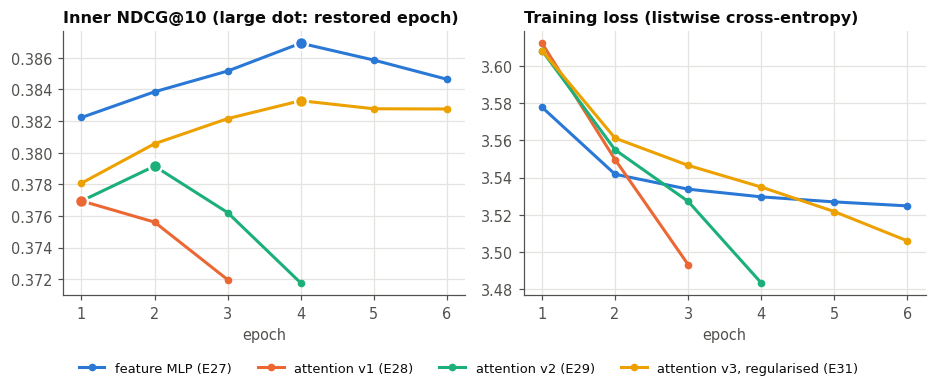

In [8]:
RUNS = {"feature MLP (E27)": "mlp", "attention v1 (E28)": "attention", "attention v2 (E29)": "attention_v2",
        "attention v3, regularised (E31)": "attention_v3"}
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.3))
for j, (label, name) in enumerate(RUNS.items()):
    path = NEURAL_DIR / f"{name}_history.csv"
    if not path.is_file():
        assert CHECK_SEARCHES, f"{path.name} is missing"
        print(f"{path.name} not found: left out (code check only)")
        continue
    history = pd.read_csv(path)
    best = history.loc[history.inner_ndcg_at_10.idxmax()]
    trained = history[history.epoch >= 1]
    axes[0].plot(trained.epoch, trained.inner_ndcg_at_10, color=SERIES[j], marker="o", markersize=4, label=label)
    axes[0].scatter(best.epoch, best.inner_ndcg_at_10, s=70, color=SERIES[j], edgecolor="white", linewidth=1.5, zorder=3)
    axes[1].plot(trained.epoch, trained.loss, color=SERIES[j], marker="o", markersize=4, label=label)
axes[0].set_title("Inner NDCG@10 (large dot: restored epoch)")
axes[1].set_title("Training loss (listwise cross-entropy)")
for ax in axes:
    ax.set_xlabel("epoch")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.02),
           ncol=4, fontsize=8.5)
save(fig, "fig5_neural_training")

## Reading the result (E32, corrected after the final reviews in E33)

- **Registry check passed:** all six logged rankings reproduce their registry values; regularised attention scores 0.3867 (its E31 row is logged when 05 section 15 next runs).
- **Where the net personal gain sits.** M1 minus base is +0.039 overall: +0.042 for shoppers active in the last 7 days, +0.018 for the others. It rises with history length (+0.026 in the shortest quartile, +0.047 in the longest) and is similar across list lengths (+0.030 to +0.044; list length forms after the query, so it only describes where the gain falls). **The 27% of searches whose list contains one of the shopper's own products carry 92% of the net summed gain** (+0.132 there; +0.0045 [0.0029, 0.0062] in the other 73%): a descriptive share, not credit to the exact-product feature. Searches with a final gap of up to 30 s (9%) carry 23% of the gain (+0.097): session evidence or post-search actions, not decidable (E30). All segment intervals are pointwise and exploratory.
- **Learning beyond "own products first" is small:** M1 minus the rule is +0.0047 overall and +0.002 to +0.006 in every segment except final gaps of up to 30 s (+0.0114 [0.0062, 0.0167]); without them +0.0040.
- **Wins and losses.** M1 ranks 22% of searches better than the base, 62% equally and 16% worse (mean loss -0.14). With an own product in the list 43% / 33% / 24%; without, 14% / 72% / 13%: there personalisation is a near-balanced reshuffle with a small net gain.
- **Candidate types and displacement.** Engaged products from the shopper's own history (8% of engaged candidates) reach the top 10 in 57% of cases under the base and 98% under M1. **Within the searches that contain an own product, the other engaged products lose 1.8 points** of top-10 probability [-2.4, -1.2] (warm 48.2% to 44.7%, cold 4.2% to 6.2%), far outweighed by the own-product gain; in the other searches they gain 0.4 points [0.1, 0.6]. Personalisation does displace other relevant products where it acts, modestly.
- **Cold products** (31% of engaged candidates; in nobody's lagged training history) reach the top 10 in only 7% (popularity) to 12% of cases under every ranking and are about half of the engaged candidates M1 misses (10,172 of 19,359; label-weighted 53%): a substantial remaining weakness that our features (no content or cold-start features) do not address. The neural models place them a little more often (MLP 11.4%, attention 11.8%; descriptive, one seed).
- **Neural training curves:** attention v1 and v2 peak at epochs 1-2 and then fall while the training loss keeps falling (overfitting); the regularised v3 rises to epoch 4 and stays flat, below the MLP throughout (one seed per model).
- **Decision:** descriptive results and report figures; no change to any model. FINDINGS 11 and PROJECT_PLAN updated (E32, E33).